# HMC-NNN Datalab — Feature engineering zonder data leakage

**Minor Data & Health Innovation · HMC-NNN**

Dit is het vervolg op [`01_base_eda_hmc_nnn.ipynb`](01_base_eda_hmc_nnn.ipynb). Daar hebben we
de data leren kennen; hier bouwen we de **modelleertabel**: één rij per opname, met alleen
kolommen die een model bij opname écht had kunnen weten.

## Waarom een apart notebook voor features?

Pijler 4 van de basis-EDA liet iets ongemakkelijks zien: **zorgplannen groeien tijdens de
opname.** Een deel van de NANDA-diagnoses krijgt pas op dag 1, 2 of 7 een Baseline-meting.

Stel je bouwt een model dat bij binnenkomst voorspelt hoe lang iemand blijft liggen, en je
geeft het `n_diagnoses_totaal` als feature. Dan vertel je het model hoeveel diagnoses er
*uiteindelijk* in het zorgplan stonden — informatie uit de toekomst. Het model wordt er
schijnbaar beter van en faalt zodra het in de praktijk wordt gebruikt. Dat heet **data
leakage**.

Het lastige is dat leakage er onschuldig uitziet. Deze kolommen uit `df_opnames` lijken
allemaal "gewoon beschrijvend", maar geen van alle mag als dag-0 feature mee:

| Kolom | Waarom niet |
|---|---|
| `n_diagnoses_totaal` | telt ook diagnoses die pas op dag 3 zijn toegevoegd |
| `n_diagnoses_actief_baseline` | kijkt naar álle Baselines, ook die van latere diagnoses |
| `baseline_score_gemiddeld` | idem — middelt over de hele opname heen |
| `Is_dagopname` | is `Opnameduur_dagen == 0`, dus letterlijk het antwoord |
| `gem_gezondheidswinst` | komt uit de Eindscore |

## Wat dit notebook oplevert

1. Een strikt afgebakende **dag-0 featuretabel** (`src/features.py`)
2. Een vergelijking tussen de dag-0 kolommen en hun onveilige tegenhangers
3. **Dummy-kolommen** voor de NANDA-diagnoses die op dag 0 liepen
4. Een **leakage-controle** die hard faalt in plaats van stil door te laten
5. Een **patiënt-gebonden** train/test-splitsing
6. `data/processed/modelleertabel_dag0.csv` als startpunt voor de modelleerstap

> **Let op — nog steeds de testset.** 10 opnames, 10 patiënten. Alles hieronder gaat over de
> *werkwijze*; getallen zijn illustratief.

## 0. Setup

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator


def vind_project_root() -> Path:
    """Zoekt omhoog vanaf de huidige map tot src/data_loader.py gevonden is."""
    for kandidaat in [Path.cwd(), *Path.cwd().parents]:
        if (kandidaat / "src" / "data_loader.py").is_file():
            return kandidaat
    raise FileNotFoundError(
        "Kan de project-root niet vinden: src/data_loader.py ontbreekt in deze map "
        "en in alle bovenliggende mappen."
    )


PROJECT_ROOT = vind_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import (
    build_admission_table,
    build_diagnosis_table,
    load_and_clean_hmc_data,
)
from src.features import (
    build_dag0_diagnose_dummies,
    build_dag0_features,
    controleer_geen_leakage,
    selecteer_dag0_metingen,
    split_op_patient,
)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

print("Project-root:", PROJECT_ROOT)

Project-root: C:\Users\qsoerohardjo\Documents\hmc-nnn


In [2]:
# Zelfde huisstijl als notebook 01, zodat alle grafieken in het project op elkaar lijken.
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECUNDAIR = "#52514e"
GRID = "#e1e0d9"
AS = "#c3c2b7"

PALET = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
         "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLAUW, ORANJE, AQUA = PALET[0], PALET[1], PALET[2]
NEUTRAAL = "#c9c8c1"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "figure.dpi": 110,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AS,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK_SECUNDAIR,
    "axes.titlecolor": INK,
    "axes.titlesize": 11.5,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "grid.linestyle": "-",
    "xtick.color": AS,
    "ytick.color": AS,
    "xtick.labelcolor": INK_SECUNDAIR,
    "ytick.labelcolor": INK_SECUNDAIR,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "DejaVu Sans", "Arial"],
    "font.size": 10,
    "lines.linewidth": 2,
    "lines.markersize": 8,
    "legend.frameon": False,
    "legend.fontsize": 9,
})


def stijl_as(ax, waarde_as="y"):
    ax.grid(axis=waarde_as, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    return ax


def hele_dagen(ax, as_naam="x"):
    as_object = ax.xaxis if as_naam == "x" else ax.yaxis
    as_object.set_major_locator(MaxNLocator(integer=True))
    return ax


def label_balken(ax, balken, waarden, horizontaal=False, suffix=""):
    for rect, waarde in zip(balken, waarden):
        if horizontaal:
            ax.text(rect.get_x() + rect.get_width(), rect.get_y() + rect.get_height() / 2,
                    f"  {waarde}{suffix}", va="center", ha="left",
                    color=INK_SECUNDAIR, fontsize=9)
        else:
            ax.text(rect.get_x() + rect.get_width() / 2, rect.get_height(),
                    f"{waarde}{suffix}", va="bottom", ha="center",
                    color=INK_SECUNDAIR, fontsize=9)

In [3]:
df = load_and_clean_hmc_data()
df_diagnoses = build_diagnosis_table(df)
df_opnames = build_admission_table(df, df_diagnoses)

print(f"Metingen : {len(df)}")
print(f"Opnames  : {df['Opnamenummer'].nunique()}")
print(f"Patienten: {df['Patientnr'].nunique()}")

Metingen : 226
Opnames  : 10
Patienten: 10


---

## 1. Wat telt als "dag 0"?

De regel die we hanteren is bewust streng:

> Een meting is dag-0-informatie wanneer `Meet_dag_van_opname == 0` **én**
> `Meetmoment == 'Baseline'`.

`Meet_dag_van_opname` is het aantal dagen tussen de meting en `Opname_startdatum`, en
`Opname_startdatum` is per definitie de vroegste meting van die opname. "Dag 0" is dus precies
de eerste dag waarop er iets geregistreerd is.

Waarom niet "de eerste meting per diagnose"? Omdat die regel juist de later toegevoegde
diagnoses binnenhaalt — en dat is exact wat we willen uitsluiten.

In [4]:
per_dag = (
    df.groupby(["Meet_dag_van_opname", "Meetmoment"])
      .size().unstack(fill_value=0)
      .rename_axis("Dag van opname")
)
dag0_baseline = int(per_dag.loc[0, "Baseline"]) if 0 in per_dag.index else 0
later_baseline = int(df[(df["Meetmoment"] == "Baseline") & (df["Meet_dag_van_opname"] > 0)].shape[0])

print(f"Baseline-metingen op dag 0      : {dag0_baseline}")
print(f"Baseline-metingen na dag 0      : {later_baseline}  <- deze gebruiken we NIET als feature")
print(f"Eindscore-metingen (altijd later): {int((df['Meetmoment'] == 'Eindscore').sum())}")
print()
per_dag

Baseline-metingen op dag 0      : 84
Baseline-metingen na dag 0      : 25  <- deze gebruiken we NIET als feature
Eindscore-metingen (altijd later): 117



Meetmoment,Baseline,Eindscore
Dag van opname,,
0,84,9
1,19,6
2,2,22
3,2,1
4,0,6
5,0,9
6,0,11
7,2,24
9,0,18


In [5]:
dag0 = selecteer_dag0_metingen(df)
print(f"selecteer_dag0_metingen() houdt {len(dag0)} van de {len(df)} rijen over "
      f"({len(dag0) / len(df) * 100:.0f}%), verdeeld over "
      f"{dag0['Opnamenummer'].nunique()} opnames.")
dag0.head(5)[["Opnamenummer", "Diagnose", "Indicator", "MeetScore", "Meetmoment",
              "Meet_dag_van_opname"]]

selecteer_dag0_metingen() houdt 84 van de 226 rijen over (37%), verdeeld over 10 opnames.


,Opnamenummer,Diagnose,Indicator,MeetScore,Meetmoment,Meet_dag_van_opname
0,1,Acute pijn,Melding van pijn,3,Baseline,0
16,1,Verstoord welbevinden,Misselijkheid,5,Baseline,0
18,1,Verstoord welbevinden,Moeheid,5,Baseline,0
30,2,Acute pijn,Beweegt zich met gemak,2,Baseline,0
32,2,Acute pijn,Melding van pijn,4,Baseline,0


---

## 2. De dag-0 featuretabel

`build_dag0_features()` bouwt één rij per opname. Elke kolom is herleidbaar tot een
Baseline-meting op de eerste opnamedag:

| Kolom | Betekenis |
|---|---|
| `heeft_dag0_meting` | staan er überhaupt dag-0 metingen in? |
| `n_metingen_dag0` | aantal dag-0 meetrijen |
| `n_diagnoses_dag0` | unieke NANDA-diagnoses die op dag 0 liepen |
| `n_indicatoren_dag0` | unieke NOC-indicatoren op dag 0 |
| `n_diagnoses_actief_dag0` | diagnoses met minstens één dag-0 indicator `< 5` (echte klacht) |
| `n_indicatoren_onder_5_dag0` | aantal dag-0 indicatoren met score `< 5` |
| `baseline_score_gem_dag0` | gemiddelde dag-0 score |
| `baseline_score_min_dag0` | laagste dag-0 score (de zwaarste klacht) |
| `pct_score_5_dag0` | aandeel dag-0 metingen dat "geen probleem" scoort |
| `icd10_hoofdcode` | eerste drie tekens van de ICD-10-code, bijv. `S72` |
| `Opnameduur_dagen` | **de doelvariabele**, geen feature |

In [6]:
features = build_dag0_features(df)
features

,Opnamenummer,Patientnr,ICD10Code,ICD10Omschrijving,icd10_hoofdcode,heeft_dag0_meting,n_metingen_dag0,n_diagnoses_dag0,n_indicatoren_dag0,n_diagnoses_actief_dag0,n_indicatoren_onder_5_dag0,baseline_score_gem_dag0,baseline_score_min_dag0,pct_score_5_dag0,Opnameduur_dagen
0,1,1,S72.00,Fractuur van femurhals; gesloten,S72,True,3,2,3,1,1,4.333333,3.0,66.666667,7
1,2,2,S32.40,Fractuur van acetabulum; gesloten,S32,True,14,5,14,4,7,4.071429,2.0,50.000000,9
2,3,3,S01.0,Open wond van behaarde hoofd,S01,True,11,2,11,2,6,4.454545,4.0,45.454545,2
3,4,4,M00.97,"Pyogene artritis, niet gespecificeerd, van enk...",M00,True,9,3,9,0,0,5.000000,5.0,100.000000,11
4,5,5,S82.80,Fracturen van overige gespecificeerde delen va...,S82,True,9,4,9,2,3,4.555556,3.0,66.666667,4
5,6,6,S72.00,Fractuur van femurhals; gesloten,S72,True,5,2,5,0,0,5.000000,5.0,100.000000,6
6,7,7,S72.00,Fractuur van femurhals; gesloten,S72,True,4,2,4,0,0,5.000000,5.0,100.000000,13
7,8,8,K59.0,Constipatie,K59,True,21,3,21,3,5,4.666667,3.0,76.190476,9
8,9,9,S72.10,Pertrochantaire fractuur; gesloten,S72,True,3,2,3,1,2,3.666667,3.0,33.333333,5
9,10,10,S92.50,Fractuur van overige teen; gesloten,S92,True,5,3,5,1,1,4.800000,4.0,80.000000,0


In [7]:
features.describe().round(2)

,Opnamenummer,Patientnr,n_metingen_dag0,n_diagnoses_dag0,n_indicatoren_dag0,n_diagnoses_actief_dag0,n_indicatoren_onder_5_dag0,baseline_score_gem_dag0,baseline_score_min_dag0,pct_score_5_dag0,Opnameduur_dagen
count,10.0,10.0,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00
mean,5.5,5.5,8.40,2.80,8.40,1.40,2.50,4.55,3.70,71.83,6.60
std,3.03,3.03,5.76,1.03,5.76,1.35,2.64,0.44,1.06,23.98,4.03
min,1.0,1.0,3.00,2.00,3.00,0.00,0.00,3.67,2.00,33.33,0.00
25%,3.25,3.25,4.25,2.00,4.25,0.25,0.25,4.36,3.00,54.17,4.25
50%,5.5,5.5,7.00,2.50,7.00,1.00,1.50,4.61,3.50,71.43,6.50
75%,7.75,7.75,10.50,3.00,10.50,2.00,4.50,4.95,4.75,95.00,9.00
max,10.0,10.0,21.00,5.00,21.00,4.00,7.00,5.00,5.00,100.00,13.00


Een opname zonder enkele dag-0 Baseline verdwijnt **niet** uit de tabel: die krijgt
`heeft_dag0_meting == False`, tellingen op `0` en scores op `NaN`. Zo zie je zulke opnames
staan en kun je bewust besluiten ze uit te sluiten, in plaats van dat ze stilletjes uit je
dataset vallen. In deze testset komt het niet voor, in de volledige export vrijwel zeker wel.

---

## 3. Dag-0 versus opnamebreed: wat scheelt het?

Dit is de kern van het notebook. Hieronder staan de dag-0 kolommen naast hun tegenhangers uit
`df_opnames`. Het verschil is precies de informatie die op het moment van opname **nog niet
bestond**.

In [8]:
vergelijking = (
    features[["Opnamenummer", "n_diagnoses_dag0", "n_diagnoses_actief_dag0",
              "baseline_score_gem_dag0", "Opnameduur_dagen"]]
    .merge(
        df_opnames[["Opnamenummer", "n_diagnoses_totaal", "n_diagnoses_actief_baseline",
                    "baseline_score_gemiddeld"]],
        on="Opnamenummer",
    )
)
vergelijking["diagnoses_erbij_na_dag0"] = (
    vergelijking["n_diagnoses_totaal"] - vergelijking["n_diagnoses_dag0"]
)
kolomvolgorde = [
    "Opnamenummer", "Opnameduur_dagen",
    "n_diagnoses_dag0", "n_diagnoses_totaal", "diagnoses_erbij_na_dag0",
    "n_diagnoses_actief_dag0", "n_diagnoses_actief_baseline",
    "baseline_score_gem_dag0", "baseline_score_gemiddeld",
]
vergelijking[kolomvolgorde].round(2)

,Opnamenummer,Opnameduur_dagen,n_diagnoses_dag0,n_diagnoses_totaal,diagnoses_erbij_na_dag0,n_diagnoses_actief_dag0,n_diagnoses_actief_baseline,baseline_score_gem_dag0,baseline_score_gemiddeld
0,1,7,2,6,4,1,3,4.33,4.47
1,2,9,5,5,0,4,4,4.07,4.07
2,3,2,2,2,0,2,2,4.45,4.45
3,4,11,3,3,0,0,0,5.00,5.00
4,5,4,4,4,0,2,2,4.56,4.56
5,6,6,2,2,0,0,0,5.00,5.00
6,7,13,2,2,0,0,0,5.00,5.00
7,8,9,3,4,1,3,4,4.67,4.46
8,9,5,2,5,3,1,3,3.67,3.67
9,10,0,3,4,1,1,1,4.80,4.80


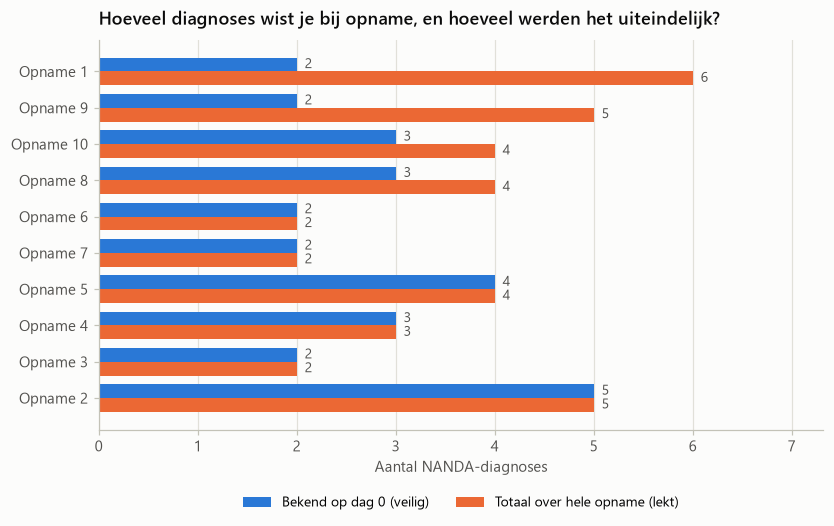

Bij 4 van de 10 opnames kwamen er na dag 0 diagnoses bij.
In totaal 9 diagnoses die een dag-0 model niet mag zien.


In [9]:
gesorteerd = vergelijking.sort_values("diagnoses_erbij_na_dag0", ascending=True)
labels = [f"Opname {int(n)}" for n in gesorteerd["Opnamenummer"]]
y = np.arange(len(labels))
hoogte = 0.38

fig, ax = plt.subplots(figsize=(8.5, 4.6))
b1 = ax.barh(y + hoogte / 2, gesorteerd["n_diagnoses_dag0"].to_numpy(), height=hoogte,
             color=BLAUW, label="Bekend op dag 0 (veilig)")
b2 = ax.barh(y - hoogte / 2, gesorteerd["n_diagnoses_totaal"].to_numpy(), height=hoogte,
             color=ORANJE, label="Totaal over hele opname (lekt)")
label_balken(ax, b1, gesorteerd["n_diagnoses_dag0"].to_numpy(), horizontaal=True)
label_balken(ax, b2, gesorteerd["n_diagnoses_totaal"].to_numpy(), horizontaal=True)

ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_title("Hoeveel diagnoses wist je bij opname, en hoeveel werden het uiteindelijk?")
ax.set_xlabel("Aantal NANDA-diagnoses")
ax.set_xlim(0, gesorteerd["n_diagnoses_totaal"].max() * 1.22)
# Onder de as, zodat de legenda nooit over de balken of hun labels valt.
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)
stijl_as(ax, "x")
hele_dagen(ax, "x")
plt.show()

gegroeid = int((vergelijking["diagnoses_erbij_na_dag0"] > 0).sum())
print(f"Bij {gegroeid} van de {len(vergelijking)} opnames kwamen er na dag 0 diagnoses bij.")
print(f"In totaal {int(vergelijking['diagnoses_erbij_na_dag0'].sum())} diagnoses die een "
      f"dag-0 model niet mag zien.")

Elke oranje balk die langer is dan de blauwe ernaast, is een opname waarbij
`n_diagnoses_totaal` het model iets vertelt wat bij binnenkomst nog niet bekend was. Dat is
geen klein detail: het is precies de informatie die correleert met "deze patiënt bleef lang
liggen", want hoe langer je ligt, hoe meer er aan je zorgplan wordt toegevoegd.

---

## 4. De inhoud van het zorgplan als feature

Tot nu toe telden we alleen **hoeveel** diagnoses er waren. Maar *welke* diagnose er staat,
zegt waarschijnlijk meer: "Mobiliteitstekort" is iets anders dan "Kennistekort".

`build_dag0_diagnose_dummies()` maakt per opname een 0/1-kolom per NANDA-diagnose die op dag 0
liep. Met `min_voorkomens` kun je zeldzame diagnoses samenvoegen in `diag_overig` — op de
volledige dataset voorkomt dat honderden kolommen die elk één keer voorkomen.

In [10]:
dummies = build_dag0_diagnose_dummies(df, min_voorkomens=1)
print(f"{dummies.shape[1] - 1} dummy-kolommen voor {dummies.shape[0]} opnames")
dummies

12 dummy-kolommen voor 10 opnames


,Opnamenummer,diag_acute_pijn,diag_acute_verwardheid,diag_angst,diag_disfunctionele_gastro_intestinale_peristaltiek,diag_huiddefect,diag_kennistekort,diag_mobiliteitstekort_lichamelijk,diag_obstipatie,diag_risico_op_acute_verwardheid,diag_risico_op_vallen_bij_volwassenen,diag_verstoord_welbevinden,diag_weefseldefect
0,1,1,0,0,0,0,0,0,0,0,0,1,0
1,2,1,0,1,0,0,0,1,1,0,0,0,1
2,3,0,0,0,0,1,0,0,0,0,0,1,0
3,4,1,0,0,0,0,0,1,0,0,0,0,1
4,5,1,0,0,0,0,0,1,0,0,0,1,1
5,6,1,1,0,0,0,0,0,0,0,0,0,0
6,7,0,0,1,0,0,1,0,0,0,0,0,0
7,8,0,0,0,1,0,0,0,0,1,1,0,0
8,9,1,0,0,0,0,0,1,0,0,0,0,0
9,10,1,0,0,0,0,0,1,0,0,0,1,0


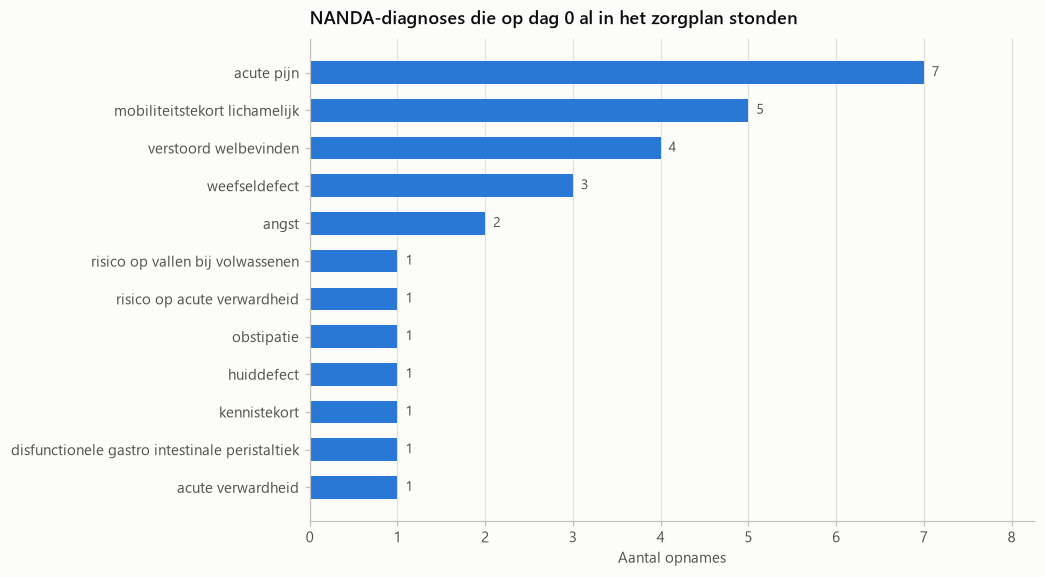

In [11]:
frequentie = (
    dummies.drop(columns="Opnamenummer").sum()
    .sort_values(ascending=True)
)
frequentie.index = [naam.removeprefix("diag_").replace("_", " ") for naam in frequentie.index]

fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(frequentie) + 1.6))
balken = ax.barh(frequentie.index, frequentie.to_numpy(), color=BLAUW, height=0.6)
label_balken(ax, balken, frequentie.to_numpy(), horizontaal=True)

ax.set_title("NANDA-diagnoses die op dag 0 al in het zorgplan stonden")
ax.set_xlabel("Aantal opnames")
ax.set_xlim(0, frequentie.max() * 1.18)
stijl_as(ax, "x")
hele_dagen(ax, "x")
plt.show()

Met 10 opnames is dit vooral een plaatje van de testset. Op de volledige dataset wordt dit de
plek waar je beslist welke diagnoses genoeg voorkomen om een eigen kolom te verdienen — zet
`min_voorkomens` dan op bijvoorbeeld 25 of 50.

---

## 5. De modelleertabel en de leakage-controle

Nu voegen we alles samen en laten we de controle erop los. `controleer_geen_leakage()` kijkt
naar **kolomnamen** en faalt zodra er iets in zit dat naar `Eindscore`, `Gezondheidswinst`,
diagnoseduur of opnamebrede totalen ruikt. Dat is een grove controle — en dat is bewust:
liever een valse alarmbel die je bewust wegklikt dan een lek dat niemand opmerkt.

In [12]:
modelleertabel = features.merge(dummies, on="Opnamenummer")
print(f"Modelleertabel: {modelleertabel.shape[0]} opnames x {modelleertabel.shape[1]} kolommen")

controleer_geen_leakage(modelleertabel)
print("Leakage-controle: geslaagd — geen verdachte kolommen.")

Modelleertabel: 10 opnames x 27 kolommen
Leakage-controle: geslaagd — geen verdachte kolommen.


In [13]:
# Doet de controle ook echt iets? We vervuilen de tabel expres met twee kolommen uit df_opnames.
vervuild = modelleertabel.merge(
    df_opnames[["Opnamenummer", "n_diagnoses_totaal", "gem_gezondheidswinst"]],
    on="Opnamenummer",
)

try:
    controleer_geen_leakage(vervuild)
    print("Onverwacht: de controle liet dit door!")
except ValueError as fout:
    print("De controle grijpt in, zoals bedoeld:\n")
    print(fout)

De controle grijpt in, zoals bedoeld:

Mogelijke data leakage: deze kolommen lijken afgeleid van informatie die op dag 0 nog niet bestond.
  - n_diagnoses_totaal (bevat: totaal)
  - gem_gezondheidswinst (bevat: gezondheidswinst)
Is de kolom toch veilig? Geef hem dan mee via extra_toegestaan.


Let op de laatste regel van de foutmelding: een kolom die **wél** veilig is maar toevallig een
verdacht woord in de naam heeft, geef je mee via `extra_toegestaan`. Zo blijft de controle
bruikbaar zonder dat je hem uitzet.

---

## 6. Splitsen op patiënt, niet op rij

Bij de stap naar modellering moet je train en test scheiden. De verleiding is om gewoon 25%
van de rijen apart te zetten — maar in de volledige HMC-dataset kan **dezelfde patiënt
meerdere opnames** hebben. Komt patiënt 412 dan zowel in train als in test, dan meet je
hoe goed je model die ene patiënt onthoudt, niet hoe goed het generaliseert.

`split_op_patient()` verdeelt daarom eerst de patiëntnummers, en pas daarna de rijen.

In [14]:
train, test = split_op_patient(modelleertabel, test_fractie=0.3, seed=42)

print(f"Train: {len(train)} opnames, {train['Patientnr'].nunique()} patienten")
print(f"Test : {len(test)} opnames, {test['Patientnr'].nunique()} patienten")

overlap = set(train["Patientnr"]) & set(test["Patientnr"])
assert not overlap, f"Patienten in zowel train als test: {overlap}"
print(f"Overlap in patienten: {len(overlap)} — zoals het hoort.")
print()
print("Opnameduur in train:", sorted(train["Opnameduur_dagen"].tolist()))
print("Opnameduur in test :", sorted(test["Opnameduur_dagen"].tolist()))

Train: 7 opnames, 7 patienten
Test : 3 opnames, 3 patienten
Overlap in patienten: 0 — zoals het hoort.

Opnameduur in train: [0, 2, 4, 5, 9, 9, 11]
Opnameduur in test : [6, 7, 13]


In deze testset heeft elke patiënt precies één opname, dus de splitsing doet hier nog niets
bijzonders. Dat is geen reden om het later te regelen: op 25.000 opnames is dit het verschil
tussen een eerlijk en een te rooskleurig testresultaat.

Let ook op de verdeling van de opnameduur: met zulke kleine aantallen kan één toevallige
splitsing een test-set opleveren die niets lijkt op de train-set. Bij de echte dataset is
herhaalde cross-validatie (op patiëntniveau) verstandiger dan één enkele split.

---

## 7. Wegschrijven en doorgeven

De modelleertabel gaat naar `data/processed/`, zodat het modelleernotebook hem kan inlezen
zonder de hele pijplijn opnieuw te draaien. De ruwe Excel blijft ongemoeid.

In [15]:
uitvoer_map = PROJECT_ROOT / "data" / "processed"
uitvoer_map.mkdir(parents=True, exist_ok=True)
uitvoer_pad = uitvoer_map / "modelleertabel_dag0.csv"

modelleertabel.to_csv(uitvoer_pad, index=False, encoding="utf-8")
print(f"Geschreven: {uitvoer_pad.relative_to(PROJECT_ROOT)}")
print(f"{modelleertabel.shape[0]} rijen x {modelleertabel.shape[1]} kolommen")

# Teruglezen als controle dat het bestand compleet en leesbaar is.
teruggelezen = pd.read_csv(uitvoer_pad)
assert teruggelezen.shape == modelleertabel.shape
print("Terugleescontrole: OK")

Geschreven: data\processed\modelleertabel_dag0.csv
10 rijen x 27 kolommen
Terugleescontrole: OK


---

## 8. Naar de modelleerstap

De tabel staat klaar. Voor `notebooks/03_modellering.ipynb`:

```python
from src.features import controleer_geen_leakage, split_op_patient

modelleertabel = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "modelleertabel_dag0.csv")
controleer_geen_leakage(modelleertabel)
train, test = split_op_patient(modelleertabel, test_fractie=0.25, seed=42)
```

**Afspraken voor dat notebook**

- `Opnameduur_dagen` is de doelvariabele; haal hem uit de features voordat je traint.
- `Opnamenummer`, `Patientnr`, `ICD10Code` en `ICD10Omschrijving` zijn sleutels en labels,
  geen features. `icd10_hoofdcode` wél — die is bedoeld om te one-hot-encoden.
- Begin met een **baseline die niets leert**: altijd de mediane opnameduur voorspellen. Elk
  model dat daar niet overheen komt, voegt niets toe.
- Vergelijk expliciet drie varianten om de onderzoeksvraag te beantwoorden:
  1. alleen ICD-10
  2. alleen NANDA/NOC dag-0 kenmerken
  3. beide samen

  Het verschil tussen (1) en (3) is wat het verpleegkundige zorgplan toevoegt bovenop de
  medische diagnose.
- Draai `controleer_geen_leakage()` opnieuw nadat je features hebt toegevoegd of samengevoegd.
  De controle kost niets en vangt precies de fout die je anders pas bij de verdediging ontdekt.